<a href="https://colab.research.google.com/github/eliezana05/-DI-Bootcamp-Stage1/blob/main/Week3/Day2/Exercises_XP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Determinant: 46.0 
Inverse:
 [[ 0.32608696 -0.10869565 -0.15217391]
 [-0.04347826  0.34782609  0.08695652]
 [-0.13043478  0.04347826  0.26086957]]
2. Mean: 0.5352327331104896 Median: 0.5151448566208843 Std: 0.2778382687810503
3. ['2023/01/01' '2023/01/02' '2023/01/03' '2023/01/04' '2023/01/05'
 '2023/01/06' '2023/01/07' '2023/01/08' '2023/01/09' '2023/01/10'
 '2023/01/11' '2023/01/12' '2023/01/13' '2023/01/14' '2023/01/15'
 '2023/01/16' '2023/01/17' '2023/01/18' '2023/01/19' '2023/01/20'
 '2023/01/21' '2023/01/22' '2023/01/23' '2023/01/24' '2023/01/25'
 '2023/01/26' '2023/01/27' '2023/01/28' '2023/01/29' '2023/01/30'
 '2023/01/31']


,A,B,C
0,83,19,80
1,0,79,78
2,78,66,47
3,70,27,78
4,55,45,50
5,56,3,13
6,24,11,43
7,66,65,47


,A,B,C
0,83,19,80
2,78,66,47
3,70,27,78
4,55,45,50
5,56,3,13
7,66,65,47


,A,B,C
sum,432.0,315.000,436.0
mean,54.0,39.375,54.5


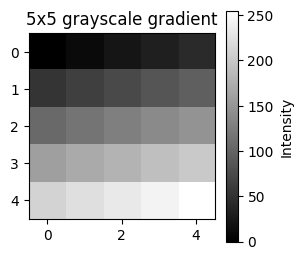

6. Mean paired change: 4.188251946843691 one-sided permutation p: 4.999750012499375e-05
Reject H0 at 5%.
Synthetic data; this is not evidence of effectiveness in real employees.
7. [ True False False  True]
8. 2023-01-01 to 2023-03-31 : 90 days; first values: [-0.0132556  -0.95500294 -0.28396263]
8. 2023-04-01 to 2023-06-30 : 91 days; first values: [ 1.63494824 -0.48439421 -1.73330402]
8. 2023-07-01 to 2023-09-30 : 92 days; first values: [-0.49172732 -0.30967994  0.51572951]
8. 2023-10-01 to 2023-12-31 : 92 days; first values: [ 0.22267631 -0.63192704  0.79825165]


,x,y,z
0,0,1,2
1,3,4,5
2,6,7,8
3,9,10,11


9. Restored array: [[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


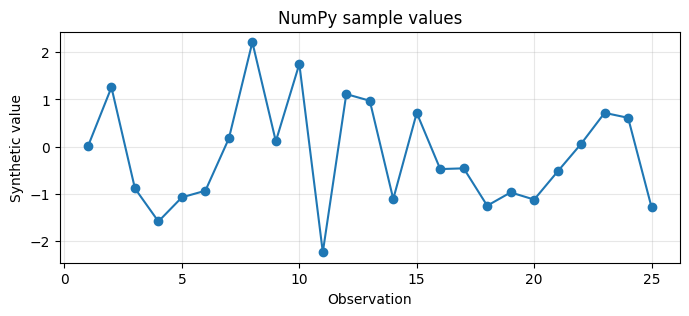

All 10 NumPy Advanced XP exercises verified successfully.


In [1]:
# Week 3 Day 2 — NumPy Advanced — Exercises XP (Octopus 3390)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
rng = np.random.default_rng(42)

# 1. Use an invertible 3x3 matrix; arange(1,10) would be singular.
A = np.array([[4., 1., 2.], [0., 3., -1.], [2., 0., 5.]])
determinant = np.linalg.det(A)
inverse = np.linalg.inv(A)
print('1. Determinant:', determinant, '\nInverse:\n', inverse)
np.testing.assert_allclose(A @ inverse, np.eye(3), atol=1e-12)
assert np.isclose(determinant, 46.)

# 2. Population standard deviation (ddof=0) of 50 synthetic values
sample = rng.random(50)
print('2. Mean:', sample.mean(), 'Median:', np.median(sample), 'Std:', sample.std())
np.testing.assert_allclose(sample.std()**2, np.mean((sample-sample.mean())**2))

# 3. January 2023 dates, half-open interval includes all 31 days
dates = np.arange(np.datetime64('2023-01-01'), np.datetime64('2023-02-01'))
formatted = np.char.replace(dates.astype(str), '-', '/')
print('3.', formatted)
assert len(dates) == 31 and formatted[-1] == '2023/01/31'

# 4. Conditional selection and aggregation
df = pd.DataFrame(rng.integers(0, 100, size=(8, 3)), columns=['A', 'B', 'C'])
selected = df.loc[df['A'] > 50]
display(df, selected, df.agg(['sum', 'mean']))
assert (selected['A'] > 50).all()

# 5. A grayscale image has shape (height,width), one intensity per pixel.
# uint8 intensities run from 0 (black) to 255 (white).
# RGB color images instead usually have shape (height,width,3).
image = np.linspace(0, 255, 25).reshape(5, 5).astype(np.uint8)
plt.figure(figsize=(3,3))
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('5x5 grayscale gradient'); plt.colorbar(label='Intensity'); plt.show()
assert image.shape == (5,5) and image.dtype == np.uint8

# 6. Paired hypothesis test: same employees before and after training.
# H0: mean change = 0. H1: mean change > 0. alpha = 0.05.
# Under H0, symmetric independent paired differences allow random sign flips.
# This NumPy Monte Carlo test preserves the paired observations.
before = rng.normal(50, 10, 30)
after = before + rng.normal(5, 3, 30)
change = after - before
observed = change.mean()
permutation_means = (rng.choice([-1, 1], size=(20000,30)) * change).mean(axis=1)
p_value = (np.count_nonzero(permutation_means >= observed) + 1) / (20000 + 1)
print('6. Mean paired change:', observed, 'one-sided permutation p:', p_value)
print('Reject H0 at 5%.' if p_value < 0.05 else 'Do not reject H0 at 5%.')
print('Synthetic data; this is not evidence of effectiveness in real employees.')
assert 0 < p_value <= 1

# 7. Element-wise comparison
first, second = np.array([3, 1, 7, 4]), np.array([2, 5, 7, 0])
comparison = first > second
print('7.', comparison)
np.testing.assert_array_equal(comparison, [True,False,False,True])

# 8. Daily time series, calendar-quarter slicing with half-open boundaries
year_dates = np.arange(np.datetime64('2023-01-01'), np.datetime64('2024-01-01'))
year_values = rng.normal(size=len(year_dates))
quarters = [('2023-01-01','2023-04-01'),('2023-04-01','2023-07-01'),('2023-07-01','2023-10-01'),('2023-10-01','2024-01-01')]
lengths = []
for start, end in quarters:
    mask = (year_dates >= np.datetime64(start)) & (year_dates < np.datetime64(end))
    subset_dates, subset_values = year_dates[mask], year_values[mask]
    lengths.append(len(subset_dates))
    print('8.', start, 'to', str(subset_dates[-1]), ':', len(subset_values), 'days; first values:', subset_values[:3])
assert lengths == [90,91,92,92] and sum(lengths) == 365

# 9. Array -> DataFrame -> array; labels belong to the DataFrame only
original = np.arange(12).reshape(4,3)
frame = pd.DataFrame(original, columns=['x','y','z'])
restored = frame.to_numpy()
display(frame); print('9. Restored array:', restored)
np.testing.assert_array_equal(restored, original)

# 10. Line chart of NumPy-generated observations
observations = rng.normal(size=25)
plt.figure(figsize=(8,3))
plt.plot(np.arange(1,26), observations, marker='o')
plt.xlabel('Observation'); plt.ylabel('Synthetic value'); plt.title('NumPy sample values'); plt.grid(alpha=0.3); plt.show()
print('All 10 NumPy Advanced XP exercises verified successfully.')
